# 3D C-Space NDF Visualization (Interactive)
This notebook uses **Plotly** to provide a high-performance interactive 3D visualization of the learned Configuration Space.

In [1]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from skimage import measure
from utils import load_model

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [3]:
model_path = "output/ndf/model_final.pt"
# Updated for optimized 256-wide multi-scale model
model = load_model(model_path, device, n_hidden=256, frequencies=[1, 2])

In [4]:
res = 64
ticks = np.linspace(-np.pi, np.pi, res)
q1, q2, q3 = np.meshgrid(ticks, ticks, ticks, indexing='ij')
grid_points = np.stack([q1.ravel(), q2.ravel(), q3.ravel()], axis=1)

with torch.no_grad():
    batch_size = 100000
    preds = []
    for i in range(0, len(grid_points), batch_size):
        batch = torch.Tensor(grid_points[i:i+batch_size]).to(device)
        p = model(batch).cpu().numpy()
        preds.append(p)
    Z = np.concatenate(preds).reshape(res, res, res)

### Interactive Mesh Rendering (Plotly)
This provides a much smoother 3D rotation experience.

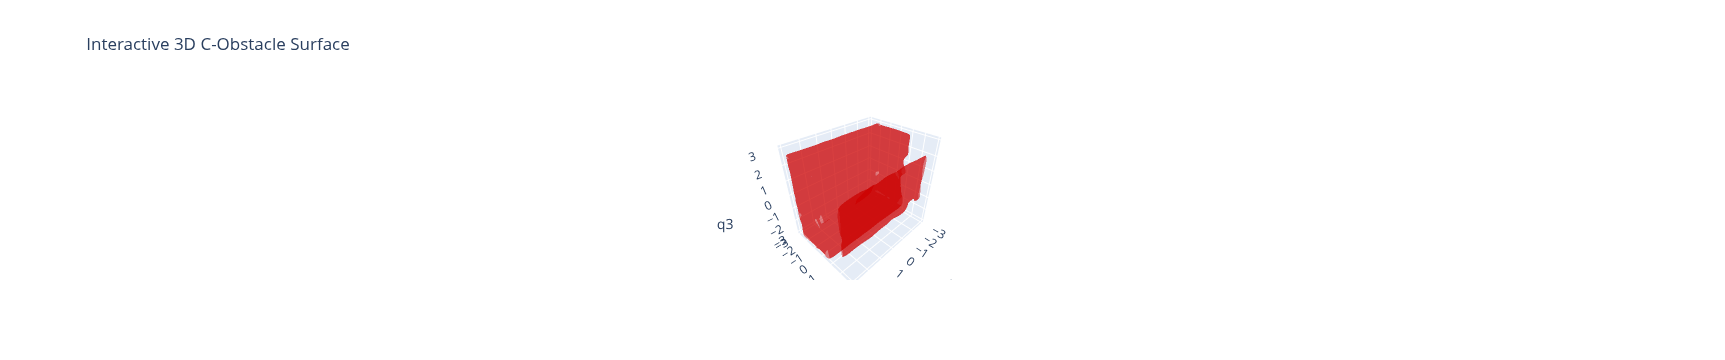

In [5]:
try:
    verts, faces, normals, values = measure.marching_cubes(Z, level=0)
    verts = (verts / (res - 1)) * (2 * np.pi) - np.pi

    fig = go.Figure(data=[go.Mesh3d(
        x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        color='red', opacity=0.5,
        flatshading=True
    )])

    fig.update_layout(
        title="Interactive 3D C-Obstacle Surface",
        scene=dict(
            xaxis_title="q1", yaxis_title="q2", zaxis_title="q3",
            xaxis=dict(range=[-np.pi, np.pi]),
            yaxis=dict(range=[-np.pi, np.pi]),
            zaxis=dict(range=[-np.pi, np.pi])
        )
    )
    fig.show()
except Exception as e:
    print(f"Mesh rendering failed: {e}")